# Prelude

In [1]:
%cd /home/mfixman/TP/MyPyCop

/home/mfixman/Dropbox/continuous/TP/MyPyCop


In [2]:
import pandas
import scipy
import numpy
import matplotlib
import seaborn
import json
import glob

from matplotlib import pyplot

from pandas import Series, DataFrame

In [3]:
seaborn.set()

# Getting Data

In [4]:
%pwd

'/home/mfixman/Dropbox/continuous/TP/MyPyCop'

In [5]:
data = pandas.concat([
    pandas.read_csv(
        'results/diagnostics_t_2.csv',
    ),
    pandas.read_csv(
      'results/literal_untie.csv',
    )
]).set_index(['problem', 'strategy'])

In [6]:
strategies = data.index.get_level_values('strategy').unique()
strategies

Index(['SATSolveLiteral', 'SATSolveLiteralFrequencyTie'], dtype='object', name='strategy')

In [7]:
# problems = data.xs(level = 'strategy', key = 'SATSolveGuided').index.str[:3].unique()
# data = data[data.index.get_level_values('problem').str[:3].isin(problems)]
# problems

In [8]:
# data = data.groupby(level = 'problem').filter(lambda x: x.solved.count() == len(strategies))

In [9]:
data.index.get_level_values('problem').str[:3].unique()

Index(['AGT', 'ALG', 'ANA', 'BOO', 'CAT', 'COL', 'COM', 'CSR', 'FLD', 'GEO',
       'GRA', 'GRP', 'HEN', 'HWV', 'KLE', 'KRS', 'LAT', 'LCL', 'LDA', 'MED',
       'MGT', 'NLP', 'NUM', 'PLA', 'PRO', 'PUZ', 'REL', 'RNG', 'SCT', 'SET',
       'SEU', 'SEV', 'SWB', 'SWC', 'SWV', 'SWW', 'SYN', 'SYO', 'TOP', 'HAL',
       'MSC', 'ROB', 'BIO', 'NUN', 'HWC', 'PHI'],
      dtype='object', name='problem')

# Analysing

In [10]:
control = ['FirstAction', 'LeanCopCut']

In [11]:
data[data.solved]

,,status,solved,steps,time_ms,info,error
problem,strategy,,,,,,
AGT002+2.p,SATSolveLiteral,solved,True,0.0,0.0,Theorem (SAT),NaN
ALG227+1.p,SATSolveLiteral,solved,True,88375.0,79013.0,Theorem (SAT); score=1.0; literal=choices:5041...,NaN
CSR062+1.p,SATSolveLiteral,solved,True,11169.0,3133.0,"Theorem (SAT); literal=choices:6449,forward:57...",NaN
FLD020-3.p,SATSolveLiteral,solved,True,53379.0,34526.0,Theorem (SAT); score=1.0; literal=choices:3177...,NaN
GEO014-2.p,SATSolveLiteral,solved,True,398.0,352.0,"Theorem (SAT); literal=choices:227,forward:145...",NaN
...,...,...,...,...,...,...,...
SYN350+1.p,SATSolveLiteralFrequencyTie,solved,True,1614.0,713.0,Theorem (SAT); score=1.0; literal=choices:1003...,NaN
SYN382+1.p,SATSolveLiteralFrequencyTie,solved,True,10.0,2.0,"Theorem (SAT); literal=choices:7,forward:10,un...",NaN
SYN660-1.p,SATSolveLiteralFrequencyTie,solved,True,21822.0,22260.0,"Theorem (SAT); literal=choices:13101,forward:9...",NaN


In [12]:
data[data.solved].groupby(level = 1).size()

strategy
SATSolveLiteral                229
SATSolveLiteralFrequencyTie    215
dtype: int64

In [13]:
solved = data['solved'].unstack('strategy')

In [14]:
solved[solved.sum(axis = 1) == 1].sum(axis = 0)

strategy
SATSolveLiteral                20
SATSolveLiteralFrequencyTie     6
dtype: int64

# Results

<Axes: xlabel='strategy'>

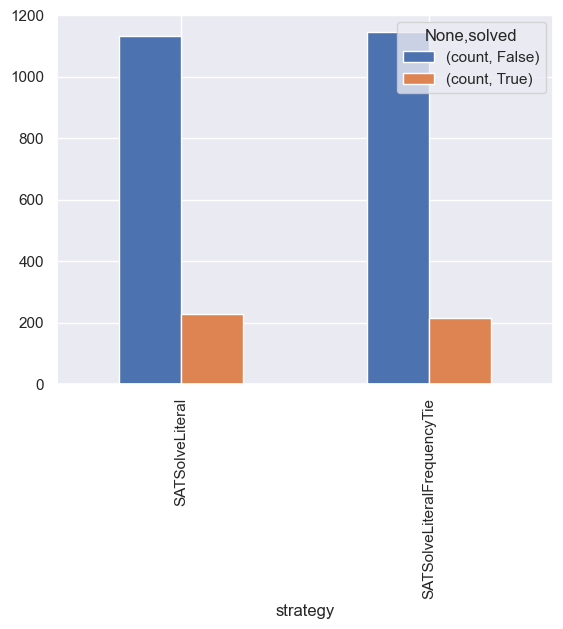

In [15]:
data.groupby(level = 'strategy').solved.value_counts().to_frame().reset_index('solved').pivot(columns = 'solved').plot.bar()

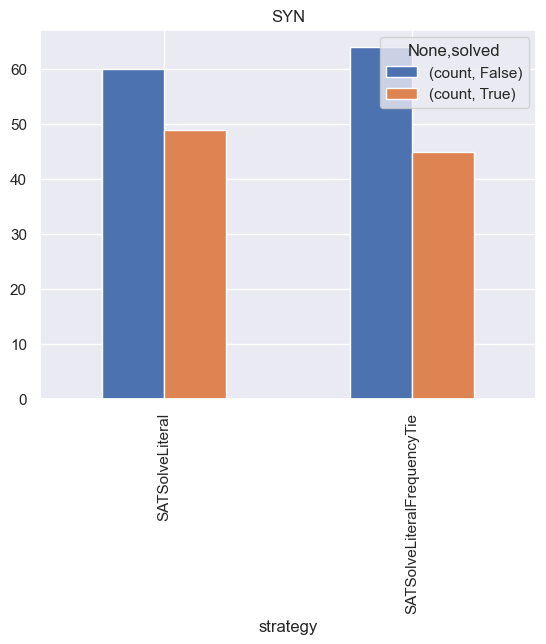

In [16]:
data[data.index.get_level_values('problem').str[:3] == 'SYN'].groupby(level = 'strategy').solved.value_counts().to_frame().reset_index('solved').pivot(columns = 'solved').plot.bar()
pyplot.title('SYN')
None

<Axes: xlabel='winner', ylabel='loser'>

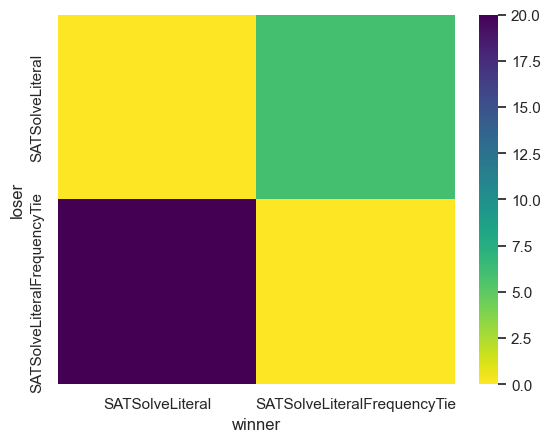

In [17]:
merged = pandas.merge(
    data.reset_index('strategy'),
    data.reset_index('strategy'),
    left_index = True,
    right_index = True,
    suffixes = ('_left', '_right'),
).set_index(['strategy_left', 'strategy_right'], append = True)

# merged = merged[merged.strategy_left < merged.strategy_right]
results = (
    merged
    [~merged.solved_left & merged.solved_right]
    .reset_index(['strategy_left', 'strategy_right'])
    [['strategy_left', 'strategy_right']]
    .value_counts()
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'loser', columns = 'winner')
)

seaborn.heatmap(results, cmap = 'viridis_r')

In [18]:
tr = {}
for problem in merged.index.get_level_values('problem').unique():
    base = problem[0:3]
    a = open(f'/home/mfixman/TP/TPTP/Problems/{base}/{problem}').readlines(100000)
    tr[problem] = sum(1 for x in a if x and not x.isspace() and x[0] != '%')

tr = Series(tr, name = 'length')
tr.index.name = 'problem'

In [19]:
statistics = (
    merged
    .xs('SATSolve', level = 'strategy_right')
    # .loc[lambda x: ~x.solved_left & x.solved_right]
    .loc[lambda x: x.index.get_level_values('problem').str.contains('-')]
    # .loc[lambda x: x.index.get_level_values('strategy_left') != 'SATSolve']
    # .groupby(level = 'problem')
    # .filter(lambda x: len(x) == 3)
    .join(tr)
    .sort_values(['steps_right', 'length'], kind = 'stable')
)
statistics.loc[lambda x: (x.steps_right == 1) & (x.steps_left > 10)].sort_values('steps_left').head(40)

KeyError: 'SATSolve'

# Analysis

In [ ]:
diffs = data[data.index.get_level_values('strategy').isin(['SATSolve', 'SATSolveGuided'])]
diffs = diffs.groupby(level = 'problem').filter(lambda x: x.solved.any() & ~x.solved.all()).sort_index()
diffs

In [ ]:
diffs.groupby(level = 'problem').filter(lambda x: x.xs(level = 'strategy', key = 'SATSolveGuided').solved)

In [ ]:
data.head()

In [ ]:
data.xs('RNG087+2.p', level = 'problem')

In [ ]:
data[data.index.get_level_values('problem').str[:3] == 'NUM'].index.get_level_values('problem').unique().sort_values()